# LightGBM lag-feature baseline vs QRA

Portfolio comparison for the WEM 5-minute price forecast. Everything here comes from `scripts/lgbm_vs_qra.py`, which:

- uses the **same origins, horizon (5 min) and frozen splits** as `scripts/qra.py`: train to 2025-09-30, calibration to 2026-03-31, test 2026-04-01 to 2026-08-18 (40,127 intervals, scored once);
- **regenerates QRA** test quantiles from the committed calibration-fitted coefficients (no refit) and checks them against the stored `qra_test.csv` / `qra_crps.csv`;
- fits **LightGBM quantile models at the same 23 levels** (0.01 to 0.99) plus an **L1 point model**, on lagged price, rolling price statistics, lagged system data and calendar features, with the frozen point-model hyperparameters. Two windows: train only, and train + calibration.

Set `RERUN = True` to refit everything (about 3 minutes on 8 cores). Otherwise the notebook reads the stored outputs.

In [1]:
import sys, subprocess, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "reports" / "forecast"
FIG = ROOT / "reports" / "figures" / "lgbm_vs_qra"
RERUN = False
if RERUN:
    subprocess.run([sys.executable, "scripts/lgbm_vs_qra.py"], cwd=ROOT, check=True)
pd.set_option("display.precision", 3)
meta = json.loads((OUT / "lgbm_vs_qra_meta.json").read_text())
{k: meta[k] for k in ("test_window", "n_test", "lgbm_params", "qra_check", "crossed_share_before_sort")}

{'test_window': ['2026-04-01 00:00:00', '2026-08-18 07:55:00'],
 'n_test': 40127,
 'lgbm_params': {'learning_rate': 0.1,
  'num_leaves': 63,
  'min_child_samples': 400,
  'n_estimators': 250},
 'qra_check': {'coverage_90': 0.9303959927231041,
  'width_90': 26.0781761386028,
  'crps_qi': 3.9208118313506546},
 'crossed_share_before_sort': {'LightGBM lag (train)': 0.9988037979415356,
  'LightGBM lag (train+cal)': 0.9975826750068533}}

## Headline table (all test origins)

In [2]:
s = pd.read_csv(OUT / "lgbm_vs_qra_summary.csv")
cols = ["model", "avg_pinball", "crps_quantile_integral", "mae_point", "coverage_50", "coverage_80", "coverage_90", "width_90", "coverage_95"]
s.loc[s.subset == "all", cols]

,model,avg_pinball,crps_quantile_integral,mae_point,coverage_50,coverage_80,coverage_90,width_90,coverage_95
0,"QRA (5 forecasts, cal-fit)",1.817,3.921,4.744,0.531,0.829,0.930,26.078,0.975
4,LightGBM lag (train),1.686,3.685,4.647,0.566,0.840,0.920,31.483,0.962
8,LightGBM lag (train+cal),1.661,3.635,4.624,0.563,0.834,0.914,30.565,0.956


## Spike periods
`spike (tail)`: price at or above the train 95th percentile (170.32 $/MWh); `spike onset`: the first interval of a spike (last price was below it). Same flags as the spike/CPS evaluation.

In [3]:
s.loc[s.subset != "all", ["model", "subset", "n", "avg_pinball", "crps_quantile_integral", "mae_point", "coverage_90", "width_90"]]

,model,subset,n,avg_pinball,crps_quantile_integral,mae_point,coverage_90,width_90
1,"QRA (5 forecasts, cal-fit)",body,36921,1.357,2.929,3.593,0.952,25.275
2,"QRA (5 forecasts, cal-fit)",spike (tail),3206,7.107,15.340,17.997,0.680,35.326
3,"QRA (5 forecasts, cal-fit)",spike onset,403,17.436,37.501,43.470,0.409,34.576
5,LightGBM lag (train),body,36921,1.249,2.740,3.517,0.918,20.420
6,LightGBM lag (train),spike (tail),3206,6.723,14.566,17.659,0.937,158.895
7,LightGBM lag (train),spike onset,403,13.233,29.290,43.235,0.757,143.907
9,LightGBM lag (train+cal),body,36921,1.215,2.669,3.465,0.912,19.182
10,LightGBM lag (train+cal),spike (tail),3206,6.799,14.766,17.974,0.940,161.654
11,LightGBM lag (train+cal),spike onset,403,13.136,29.068,42.902,0.767,141.990


## Bootstrap ranges (90%, moving block) for the CRPS difference vs QRA, and MAE differences

In [4]:
display(pd.read_csv(OUT / "lgbm_vs_qra_bootstrap.csv"))
mb = pd.read_csv(OUT / "lgbm_vs_qra_mae_bootstrap.csv")
mb[mb.model == "LightGBM lag (train)"]

,model,subset,crps_diff_vs_qra,boot_p05,boot_p95
0,LightGBM lag (train),all,-0.236,-0.292,-0.183
1,LightGBM lag (train),body,-0.189,-0.214,-0.165
2,LightGBM lag (train),spike (tail),-0.774,-1.315,-0.254
3,LightGBM lag (train),spike onset,-8.211,-10.821,-5.199
4,LightGBM lag (train+cal),all,-0.286,-0.350,-0.227
5,LightGBM lag (train+cal),body,-0.261,-0.284,-0.235
6,LightGBM lag (train+cal),spike (tail),-0.574,-1.179,-0.038
7,LightGBM lag (train+cal),spike onset,-8.433,-10.965,-5.505


,model,reference,subset,mae_diff,boot_p05,boot_p95
0,LightGBM lag (train),persistence,all,-0.098,-0.143,-0.037
1,LightGBM lag (train),persistence,body,-0.251,-0.293,-0.204
2,LightGBM lag (train),persistence,spike (tail),1.656,1.236,2.094
3,LightGBM lag (train),persistence,spike onset,-2.596,-3.098,-1.923
4,LightGBM lag (train),QRA median,all,-0.097,-0.123,-0.071
5,LightGBM lag (train),QRA median,body,-0.076,-0.087,-0.063
6,LightGBM lag (train),QRA median,spike (tail),-0.339,-0.628,-0.018
7,LightGBM lag (train),QRA median,spike onset,-0.235,-0.729,0.216
8,LightGBM lag (train),repo LightGBM point,all,-0.106,-0.136,-0.079
9,LightGBM lag (train),repo LightGBM point,body,-0.082,-0.094,-0.068


## Pinball loss per quantile level

In [5]:
pl = pd.read_csv(OUT / "lgbm_vs_qra_pinball_by_level.csv")
pl[pl.subset == "all"].pivot(index="level", columns="model", values="pinball")

model,LightGBM lag (train),LightGBM lag (train+cal),"QRA (5 forecasts, cal-fit)"
level,,,
0.010,0.289,0.271,0.481
0.025,0.550,0.531,0.770
0.050,0.873,0.854,1.053
0.100,1.342,1.317,1.444
0.150,1.666,1.634,1.726
0.200,1.878,1.839,1.930
0.250,2.027,1.980,2.073
0.300,2.152,2.104,2.176
0.350,2.214,2.197,2.243


## Figures

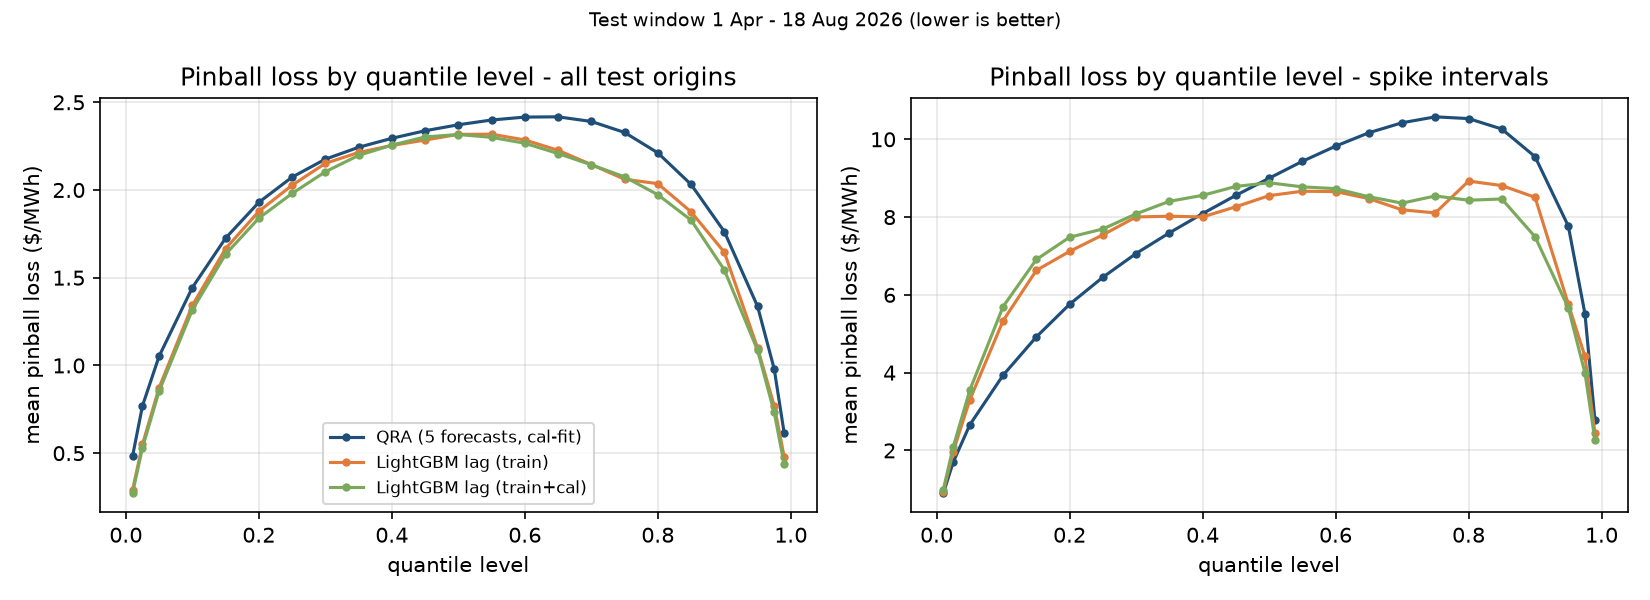

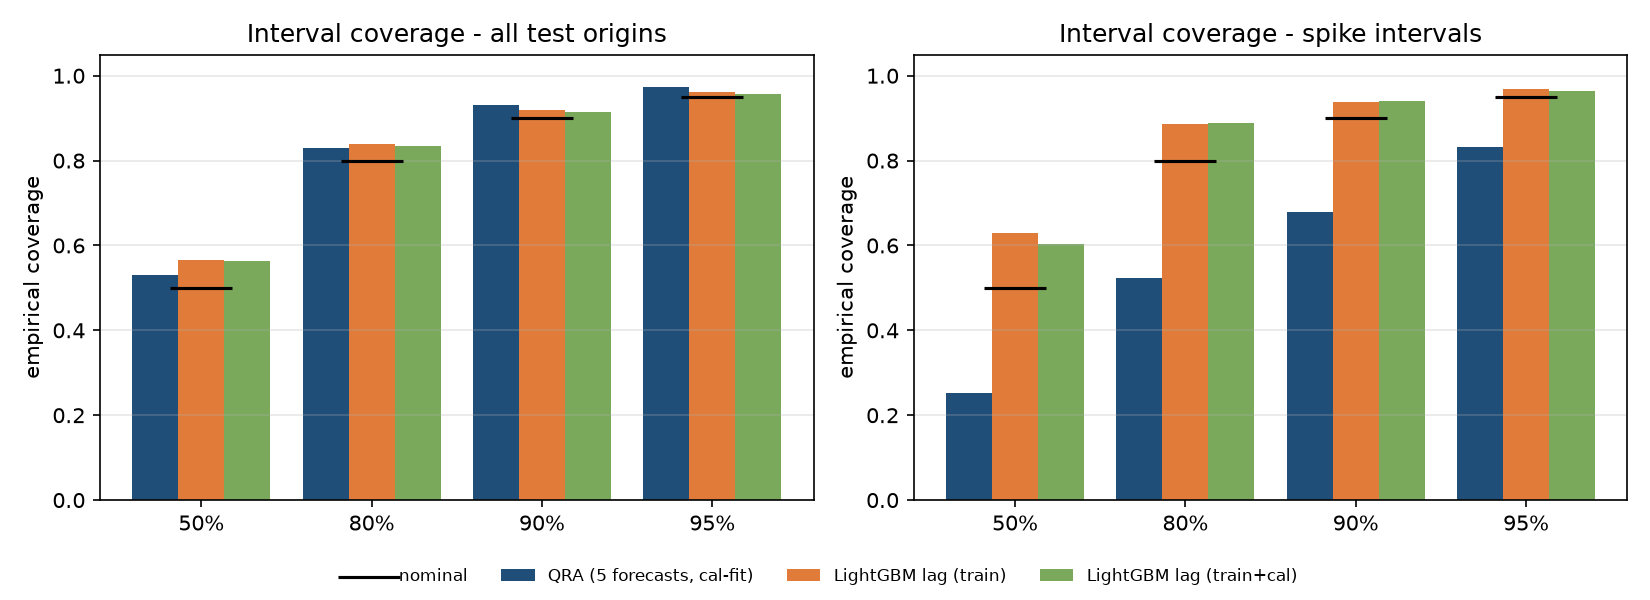

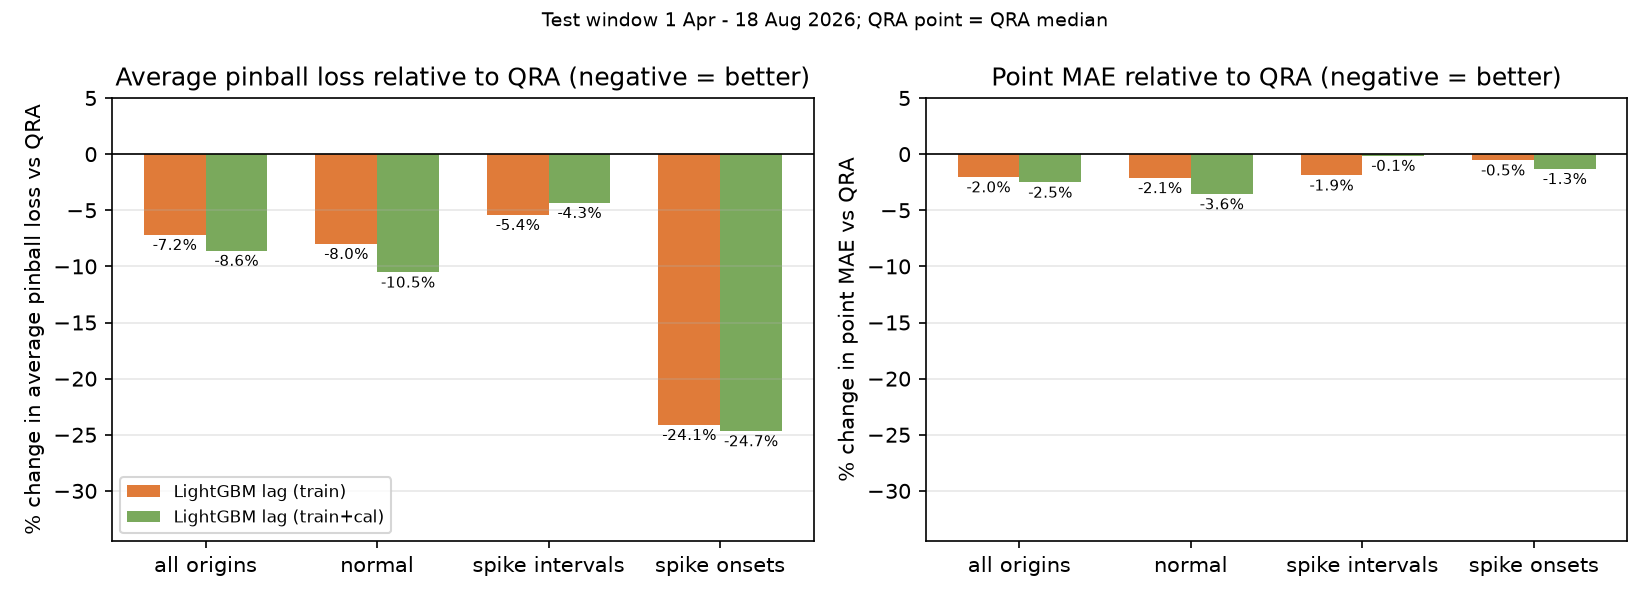

In [6]:
for name in ("pinball_by_level.png", "interval_coverage.png", "relative_to_qra_by_period.png"):
    display(Image(filename=str(FIG / name)))

## Top features of the LightGBM point model (gain)

In [7]:
pd.read_csv(OUT / "lgbm_vs_qra_point_feature_gain.csv").head(12)

,feature,gain
0,rtp_last_complete,73984.435
1,hour,51288.830
2,mcp_lag_5min,45920.913
3,month,25981.381
4,mcp_roll_mean_30min,21623.802
5,mcp_roll_std_30min,10436.648
6,mcp_lag_10min,10299.013
7,withdrawal_lag_5min,9849.657
8,mcp_roll_std_60min,9309.932
9,mcp_lag_15min,7765.350


## Reading the results

- LightGBM beats QRA on average pinball loss and quantile-integral CRPS overall, in normal periods, in spike intervals and most of all at spike onsets. Every 90% block-bootstrap range for the CRPS difference is below zero.
- QRA is a linear combination of point forecasts, so its interval width barely changes when a spike is coming and it under-covers spikes (0.68 at 90%). LightGBM widens its intervals around spikes, which gives about 0.94 coverage on spike intervals, at the cost of wide intervals there.
- Point accuracy gains are small (about 2% MAE). Within spike intervals, plain persistence is still the better point forecast.
- The 23 independent quantile models cross on almost every row before sorting. Sorting fixes this, but a joint model or monotone constraints would be cleaner.